<a href="https://colab.research.google.com/github/CameronBuckles/Final-Project-Data-Analytics-with-Python/blob/main/CBuckles_Final_Project_Data_Analytics_with_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import f_oneway

##Find a Dataset

##Ingest the Data

In [33]:
df = pd.read_csv('dragon_ball_z.csv')

In [34]:
df.head()

,Name,Race,Gender,Power Level,Ki Blast,Melee Combat,Speed,Special Attack,Transformation
0,Goku,Saiyan,Male,9000,Kamehameha,Dragon Fist,Fast,Spirit Bomb,Super Saiyan
1,Vegeta,Saiyan,Male,8500,Galick Gun,Big Bang,Fast,Final Flash,Super Saiyan
2,Piccolo,Namekian,Male,8000,Special Beam Cannon,Namekian Punch,Fast,Hellzone Grenade,Fuse with Kami
3,Gohan,Half-Saiyan,Male,7500,Masenko,Soaring Dragon Strike,Fast,Father-Son Kamehameha,Super Saiyan 2
4,Future Trunks,Half-Saiyan,Male,7800,Burning Attack,Sword Strike,Fast,Heat Dome Attack,Super Saiyan


##Final Project: Data Analytics with Python


##Data Cleaning

In [35]:
# Check the original dataset information
print("Original Dataset Information:")
df.info()

Original Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70 entries, 0 to 69
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Name            70 non-null     object
 1   Race            70 non-null     object
 2   Gender          70 non-null     object
 3   Power Level     70 non-null     int64 
 4   Ki Blast        48 non-null     object
 5   Melee Combat    59 non-null     object
 6   Speed           69 non-null     object
 7   Special Attack  37 non-null     object
 8   Transformation  70 non-null     object
dtypes: int64(1), object(8)
memory usage: 5.1+ KB


In [36]:
# Check for missing values in each column
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
Name               0
Race               0
Gender             0
Power Level        0
Ki Blast          22
Melee Combat      11
Speed              1
Special Attack    33
Transformation     0
dtype: int64


In [37]:
print("\nDuplicate Rows:")
print(df.duplicated().sum())


Duplicate Rows:
2


In [38]:
df = df.drop_duplicates()

In [39]:
# Double-check the original dataset information
print("Original Dataset Information:")
df.info()

Original Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 68 entries, 0 to 69
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Name            68 non-null     object
 1   Race            68 non-null     object
 2   Gender          68 non-null     object
 3   Power Level     68 non-null     int64 
 4   Ki Blast        48 non-null     object
 5   Melee Combat    57 non-null     object
 6   Speed           67 non-null     object
 7   Special Attack  37 non-null     object
 8   Transformation  68 non-null     object
dtypes: int64(1), object(8)
memory usage: 5.3+ KB


##Data Manipulation

Sorting

In [40]:
# Sort characters by Power Level from highest to lowest
# This allows us to identify the strongest characters
sorted_df = df.sort_values(
    by='Power Level',
    ascending=False
)
print("Characters Sorted by Power Level:")
print(sorted_df[['Name', 'Race', 'Power Level']].head(10))

Characters Sorted by Power Level:
             Name         Race  Power Level
68          Vados        Angel       200000
69           Whis        Angel       200000
39  Captain Ginyu        Alien       120000
53          Broly       Saiyan       100000
54         Cooler  Frost Demon        50000
32           Nail     Namekian        42000
40         Burter        Alien        40000
42          Guldo        Alien        40000
41        Recoome        Alien        40000
51         Bojack        Alien        40000


Filtering

In [41]:
# Filter the dataset to show characters with a Power Level
# greater than 100,000
powerful_characters = df[df['Power Level'] > 100000]
print("\nCharacters with Power Level Above 100,000:")
print(powerful_characters[['Name', 'Race', 'Power Level']])


Characters with Power Level Above 100,000:
             Name   Race  Power Level
39  Captain Ginyu  Alien       120000
68          Vados  Angel       200000
69           Whis  Angel       200000


Grouping

In [42]:
# Sort races by average Power Level from highest to lowest
race_power = df.groupby('Race')['Power Level'].mean()
race_power = race_power.sort_values(ascending=False)
print("\nAverage Power Level by Race:")
print(race_power)


Average Power Level by Race:
Race
Angel            200000.000000
Alien             40500.000000
Frost Demon       31000.000000
Saiyan            19500.000000
Majin             15000.000000
Namekian          13750.000000
Demon              9275.000000
Android            7680.000000
Half-Saiyan        7650.000000
Bio-Android        7000.000000
Kai                5000.000000
Wizard             2000.000000
Genie              1000.000000
Human               742.105263
Monkey              100.000000
Shape-shifter         7.500000
Grasshopper           5.000000
Name: Power Level, dtype: float64


##Data Visualization

/tmp/ipython-input-1050938612.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(move_counts.index, rotation=45, ha="right", fontsize=9)


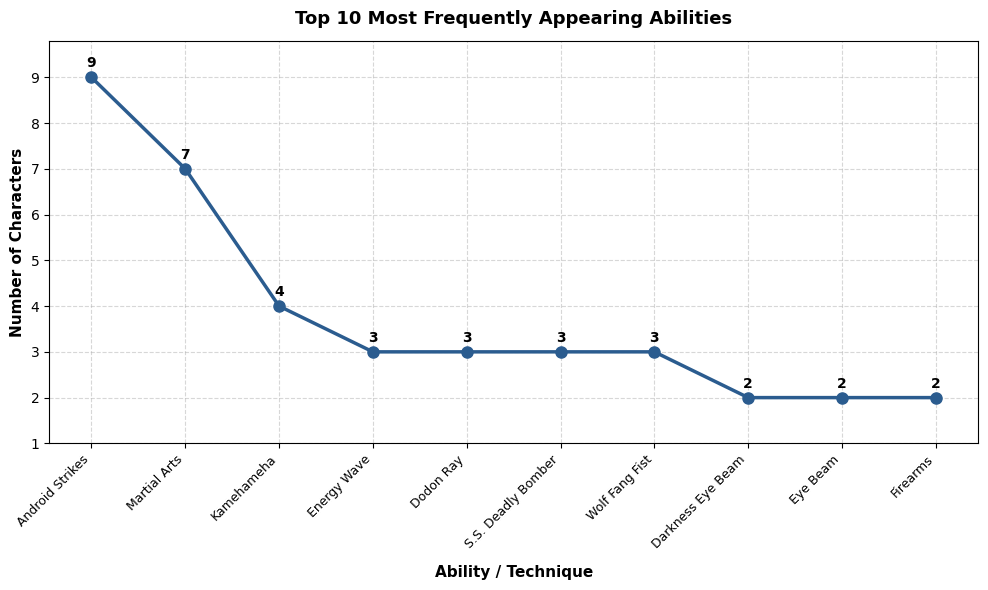

In [48]:
# 1. Load dataset and remove duplicate character entries
df = (
    pd.read_csv("dragon_ball_z.csv")
    .drop_duplicates(subset=["Name"])
    .reset_index(drop=True)
)

# 2. Extract and combine abilities across Ki Blast, Melee Combat, and Special Attack
abilities = ["Ki Blast", "Melee Combat", "Special Attack"]
all_moves = []

for col in abilities:
  moves = df[col].dropna()
  moves = moves[moves != "-"]
  all_moves.extend(moves.tolist())

# 3. Calculate frequencies for top 10 abilities
move_counts = pd.Series(all_moves).value_counts().head(10)

# 4. Create the plot
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    move_counts.index,
    move_counts.values,
    marker="o",
    color="#2b5c8f",
    linewidth=2.5,
    markersize=8,
)

# Formatting title and labels
ax.set_title(
    "Top 10 Most Frequently Appearing Abilities",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
ax.set_xlabel("Ability / Technique", fontsize=11, fontweight="bold", labelpad=10)
ax.set_ylabel("Number of Characters", fontsize=11, fontweight="bold")
ax.set_xticklabels(move_counts.index, rotation=45, ha="right", fontsize=9)
ax.grid(True, linestyle="--", alpha=0.5)

# Annotate each point with its exact value
for i, (name, val) in enumerate(move_counts.items()):
  ax.annotate(
      str(val),
      (i, val + 0.15),
      ha="center",
      va="bottom",
      fontweight="bold",
      fontsize=10,
  )

ax.set_ylim(1, 9.8)
plt.tight_layout()
plt.savefig('Top_ten_abilities.png')
plt.show()

This line chart with markers was selected to map frequency ranks across the top abilities abilities highlighted in the dataset, highlighting the sharp drop off from common techniques to rare moves. It effectively demonstrates that common physical abilities like Android Strikes (9 characters) and Martial Arts (7 characters) appear far more frequently than signature attacks like the Kamehameha (4 characters).

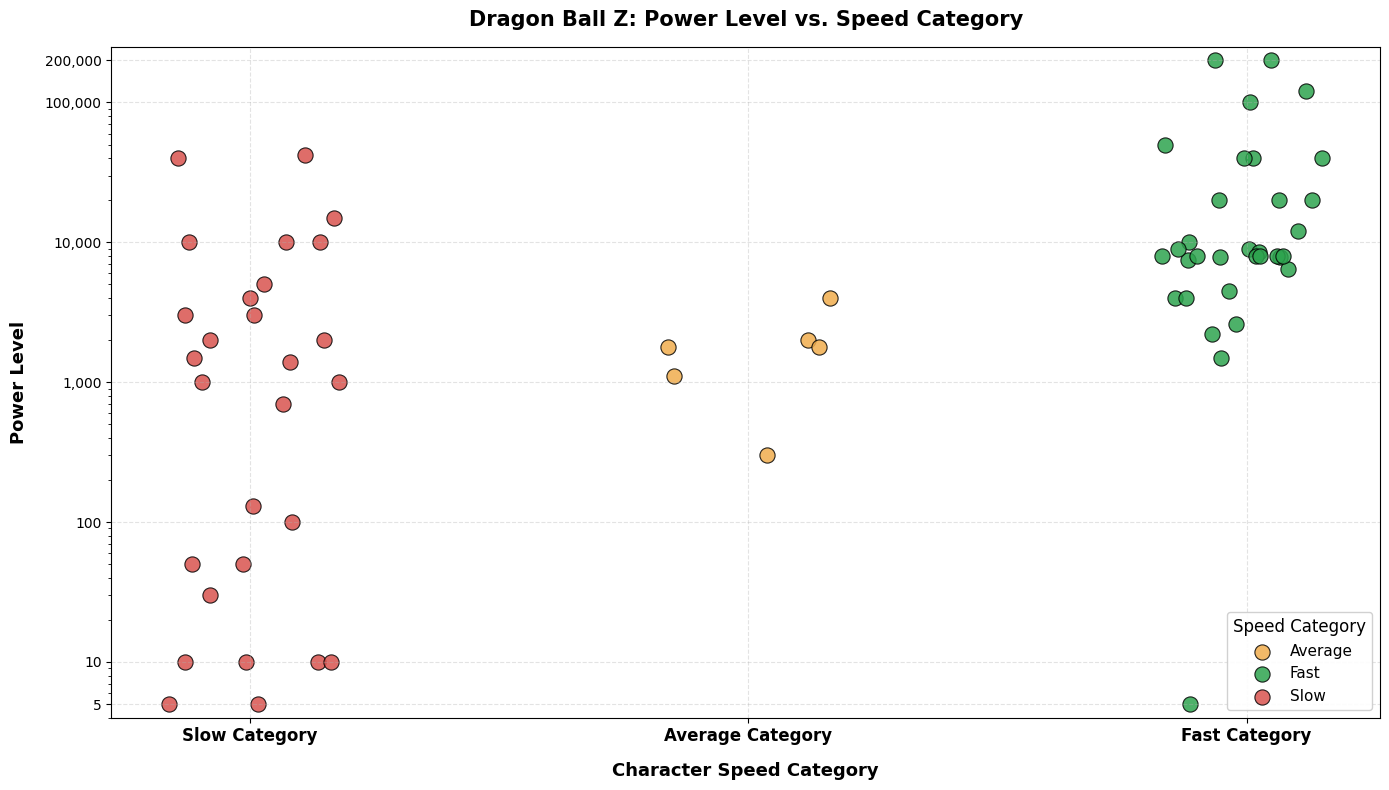

In [52]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd

# 1. Load dataset and remove duplicate character entries
df = (
    pd.read_csv("dragon_ball_z.csv")
    .drop_duplicates(subset=["Name"])
    .reset_index(drop=True)
)

# 2. Filter valid speed entries and map to numerical categories
df_clean = df.dropna(subset=["Speed"]).copy()
speed_map = {"Slow": 1, "Average": 2, "Fast": 3}
df_clean["Speed_Num"] = df_clean["Speed"].map(speed_map)

# 3. Apply horizontal jitter to prevent point overlaps
np.random.seed(101)
df_clean["Speed_Jitter"] = df_clean["Speed_Num"] + np.random.uniform(
    -0.18, 0.18, size=len(df_clean)
)

# 4. Create Plot
fig, ax = plt.subplots(figsize=(14, 8))
colors = {"Slow": "#d9534f", "Average": "#f0ad4e", "Fast": "#2ea44f"}

for speed_cat, group in df_clean.groupby("Speed"):
  ax.scatter(
      group["Speed_Jitter"],
      group["Power Level"],
      c=colors[speed_cat],
      label=speed_cat,
      s=120,
      alpha=0.85,
      edgecolors="black",
      linewidth=0.8,
  )

# 5. Set logarithmic scale and format Y-axis labels without scientific notation
ax.set_yscale("log")
yticks = [5, 10, 100, 1000, 10000, 100000, 200000]
ax.set_yticks(yticks)
ax.get_yaxis().set_major_formatter(FuncFormatter(lambda x, p: f"{int(x):,}"))
ax.set_ylim(4, 250000)

# 6. Formatting labels and grid
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(
    ["Slow Category", "Average Category", "Fast Category"],
    fontsize=12,
    fontweight="bold",
)
ax.set_xlabel(
    "Character Speed Category", fontsize=13, fontweight="bold", labelpad=12
)
ax.set_ylabel("Power Level", fontsize=13, fontweight="bold", labelpad=12)
ax.set_title(
    "Dragon Ball Z: Power Level vs. Speed Category",
    fontsize=15,
    fontweight="bold",
    pad=15,
)
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend(
    title="Speed Category",
    loc="lower right",
    frameon=True,
    facecolor="white",
    framealpha=0.9,
    fontsize=11,
    title_fontsize="12",
)

plt.tight_layout()
plt.savefig('power_vs_speed.png')
plt.show()

/tmp/ipython-input-2322384618.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(move_counts.index, rotation=45, ha="right", fontsize=9)


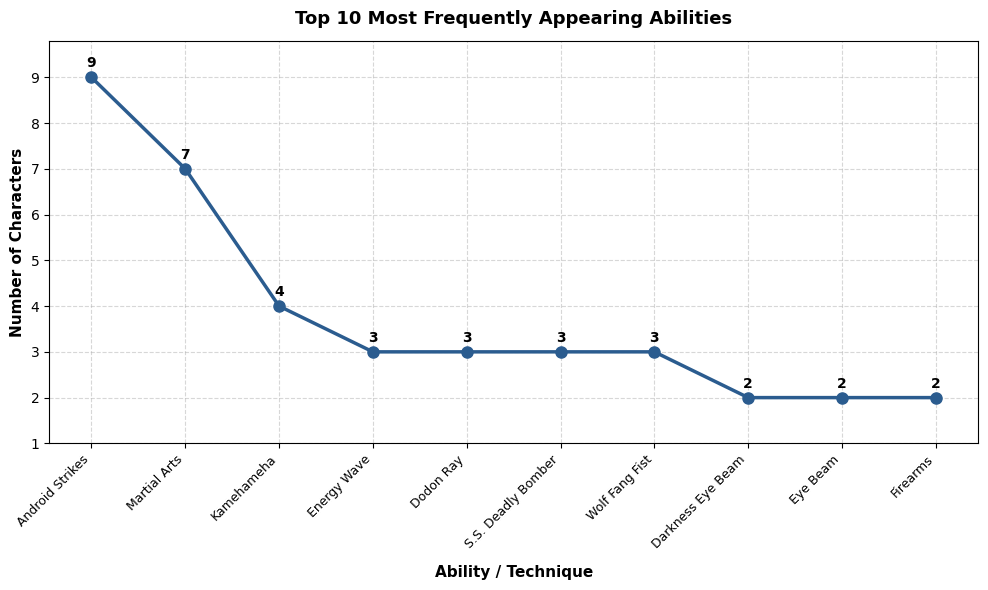

In [51]:
# 1. Load dataset and remove duplicate character entries
df = (
    pd.read_csv("dragon_ball_z.csv")
    .drop_duplicates(subset=["Name"])
    .reset_index(drop=True)
)

# 2. Extract and combine abilities across Ki Blast, Melee Combat, and Special Attack
abilities = ["Ki Blast", "Melee Combat", "Special Attack"]
all_moves = []

for col in abilities:
  moves = df[col].dropna()
  moves = moves[moves != "-"]
  all_moves.extend(moves.tolist())

# 3. Calculate frequencies for top 10 abilities
move_counts = pd.Series(all_moves).value_counts().head(10)

# 4. Create the plot
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    move_counts.index,
    move_counts.values,
    marker="o",
    color="#2b5c8f",
    linewidth=2.5,
    markersize=8,
)

# Formatting title and labels
ax.set_title(
    "Top 10 Most Frequently Appearing Abilities",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
ax.set_xlabel("Ability / Technique", fontsize=11, fontweight="bold", labelpad=10)
ax.set_ylabel("Number of Characters", fontsize=11, fontweight="bold")
ax.set_xticklabels(move_counts.index, rotation=45, ha="right", fontsize=9)
ax.grid(True, linestyle="--", alpha=0.5)

# Annotate each point with its exact value
for i, (name, val) in enumerate(move_counts.items()):
  ax.annotate(
      str(val),
      (i, val + 0.15),
      ha="center",
      va="bottom",
      fontweight="bold",
      fontsize=10,
  )

ax.set_ylim(1, 9.8)
plt.tight_layout()
plt.savefig('top_ten_abilities.png')
plt.show()

This scatter plot shows the relationship between power level and characters speeds and it accurately captures the dataset's extreme power level range from 5 to 200,000. Together, they demonstrate that high power levels strongly correlate with fast speed categories and low power levels cluster predominantly in lower tiers.

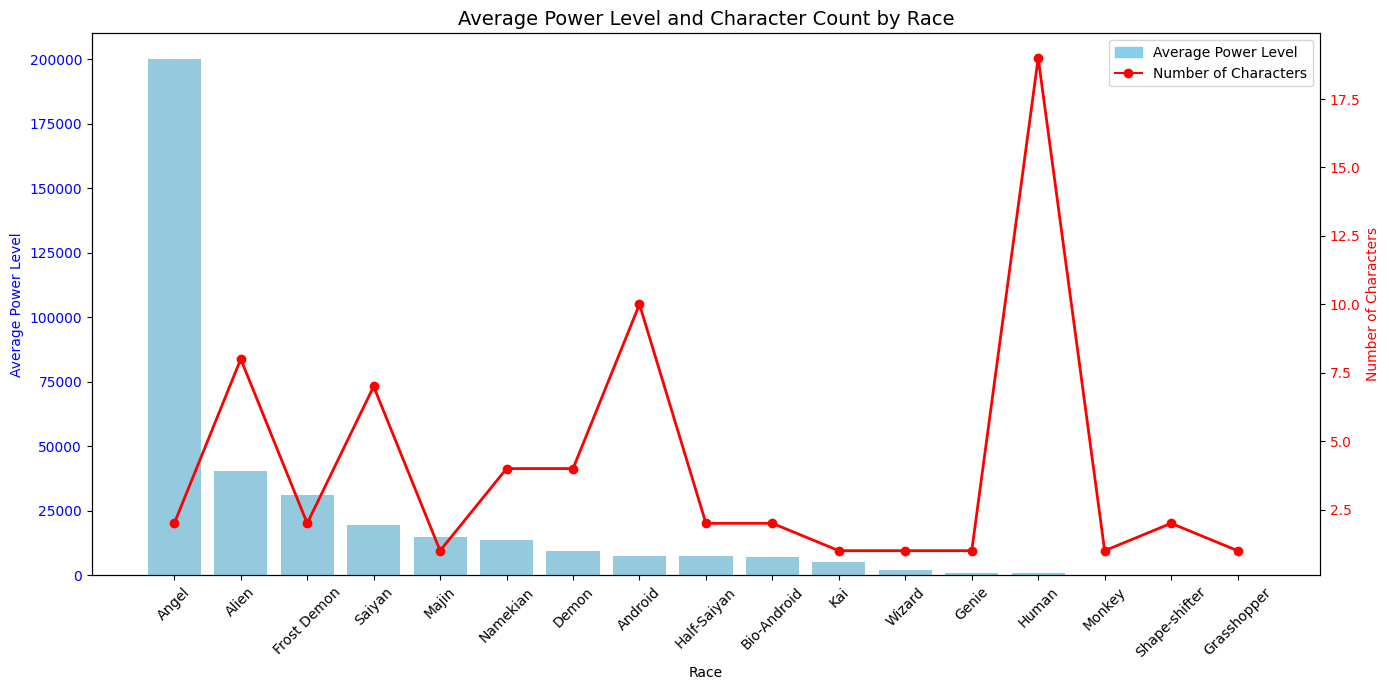

In [50]:

# Blue bars = Average Power Level
# Red line = Number of Characters

fig, ax1 = plt.subplots(figsize=(14, 7))

# Calculate average Power Level and character count by Race
race_power = df.groupby('Race')['Power Level'].mean().sort_values(ascending=False)
race_count = df.groupby('Race').size()

# Create bar chart for average Power Level
sns.barplot(
    x=race_power.index,
    y=race_power.values,
    color='skyblue',
    ax=ax1
)

ax1.set_title('Average Power Level and Character Count by Race', fontsize=14)
ax1.set_xlabel('Race')
ax1.set_ylabel('Average Power Level', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.tick_params(axis='x', rotation=45)

# Create second y-axis for character count
ax2 = ax1.twinx()

# Add line chart for character count
ax2.plot(
    race_power.index,
    race_count.reindex(race_power.index),
    color='red',
    marker='o',
    linewidth=2,
    label='Number of Characters'
)

ax2.set_ylabel('Number of Characters', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Add legend
from matplotlib.lines import Line2D

legend_elements = [
    plt.Rectangle((0, 0), 1, 1, color='skyblue', label='Average Power Level'),
    Line2D([0], [0], color='red', marker='o', label='Number of Characters')
]

ax1.legend(handles=legend_elements, loc='upper right')

plt.tight_layout()
plt.savefig('average_power_by_race.png')
plt.show()


This dual chart is useful because it allows us to compare the average Power Level and number of characters within each race. It helps us identify whether races with more characters also tend to have higher average Power Levels. We can also see which races have fewer characters but higher average strength. This provides two different perspectives on the dataset in one visualization. Overall, it helps us better understand the differences in character strength across the various races.

##Statistical Analysis

Descriptive statistics

In [46]:
# Calculate descriptive statistics for character Power Levels
print("Mean:", df['Power Level'].mean())
print("Median:", df['Power Level'].median())
print("Mode:", df['Power Level'].mode()[0])
print("Standard Deviation:", df['Power Level'].std())

# Display a summary of the Power Level data
print(df['Power Level'].describe())

Mean: 17028.235294117647
Median: 4250.0
Mode: 8000
Standard Deviation: 38307.808542734405
count        68.000000
mean      17028.235294
std       38307.808543
min           5.000000
25%        1075.000000
50%        4250.000000
75%       10000.000000
max      200000.000000
Name: Power Level, dtype: float64


Distribution analysis

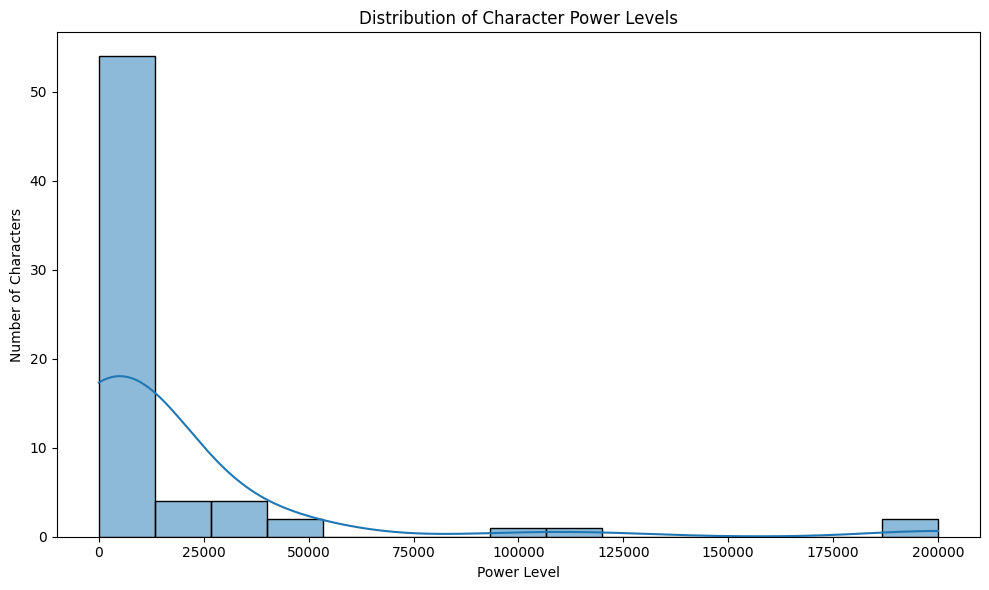

In [47]:
# A histogram to see how character Power Levels are distributed
plt.figure(figsize=(10, 6))

sns.histplot(data=df, x='Power Level', bins=15, kde=True)

plt.title('Distribution of Character Power Levels')
plt.xlabel('Power Level')
plt.ylabel('Number of Characters')

plt.tight_layout()
plt.show()

Correlation analysis

Average Power Level by Race:
Race
Angel            200000.000000
Alien             40500.000000
Frost Demon       31000.000000
Saiyan            19500.000000
Majin             15000.000000
Namekian          13750.000000
Demon              9275.000000
Android            7680.000000
Half-Saiyan        7650.000000
Bio-Android        7000.000000
Kai                5000.000000
Wizard             2000.000000
Genie              1000.000000
Human               685.952381
Monkey              100.000000
Shape-shifter         7.500000
Grasshopper           5.000000
Name: Power Level, dtype: float64


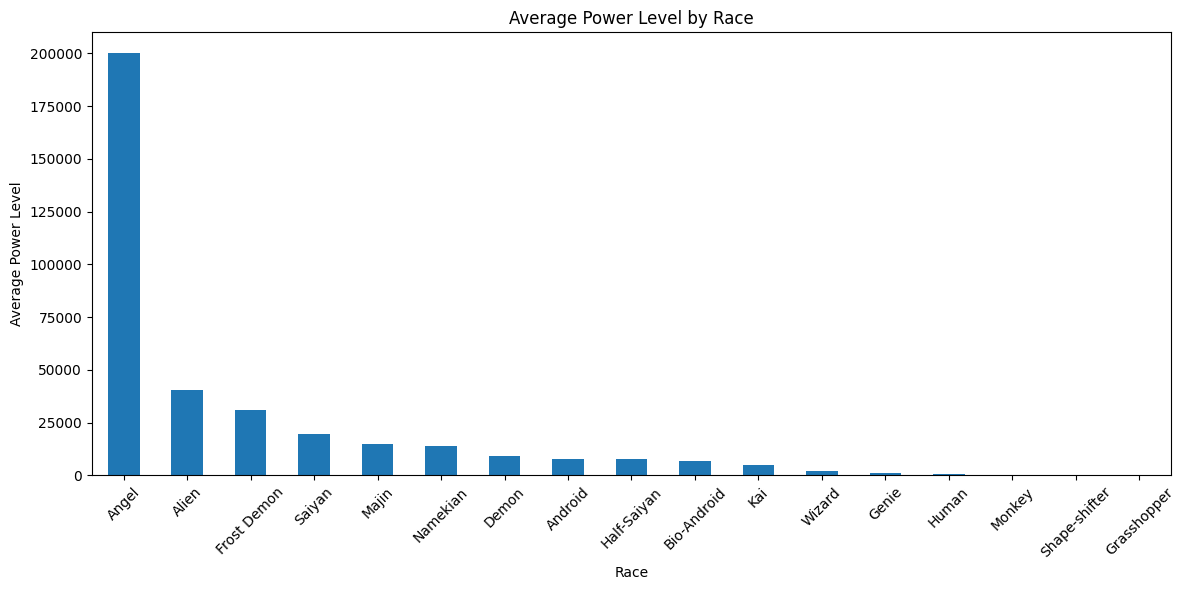

Eta: 0.9034936569688646
Eta Squared: 0.8163007881829724
F-statistic: 14.71969495192717
P-value: 3.874810334778308e-14


In [31]:
# Calculate average Power Level for each race
race_power = df.groupby("Race")["Power Level"].mean().sort_values(ascending=False)

# Display average Power Level
print("Average Power Level by Race:")
print(race_power)

# Create bar chart
race_power.plot(kind="bar", figsize=(12, 6))

plt.title("Average Power Level by Race")
plt.xlabel("Race")
plt.ylabel("Average Power Level")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Calculate correlation ratio
grand_mean = df["Power Level"].mean()

ss_between = sum(
    len(group) * (group.mean() - grand_mean) ** 2
    for _, group in df.groupby("Race")["Power Level"]
)

ss_total = sum((df["Power Level"] - grand_mean) ** 2)

eta_squared = ss_between / ss_total
eta = np.sqrt(eta_squared)

print("Eta:", eta)
print("Eta Squared:", eta_squared)

# ANOVA test
groups = [
    group["Power Level"].values
    for _, group in df.groupby("Race")
]

f_stat, p_value = f_oneway(*groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)

Null Hypothesis: There is no statistically significant relationship between character race and Power Level.

Alternative Hypothesis: There is a statistically significant relationship between character race and Power Level.

The p-value of 3.8748e-14 indicates that there is a statistically significant relationship between race and Power Level. Since the p-value is much smaller than 0.05, we can reject the null hypothesis. This suggests that different races tend to have significantly different Power Levels. However, the p-value tells us that a relationship exists, not how strong that relationship is.